In [1]:
%env HF_HOME=/blue/uf-eig/FILLMEIN/cache/
%env TORCH_HOME=/blue/uf-eig/FILLMEIN/cache/
%env HF_HUB_CACHE=/blue/uf-eig/FILLMEIN/cache/huggingface/hub
%env HF_XET_CACHE=/blue/uf-eig/FILLMEIN/cache/huggingface/xet
%env DATA_ROOT=/blue/uf-eig/FILLMEIN/HSR-Replication/datasets

env: HF_HOME=/blue/uf-eig/FILLMEIN/cache/
env: TORCH_HOME=/blue/uf-eig/FILLMEIN/cache/
env: HF_HUB_CACHE=/blue/uf-eig/FILLMEIN/cache/huggingface/hub
env: HF_XET_CACHE=/blue/uf-eig/FILLMEIN/cache/huggingface/xet
env: DATA_ROOT=/blue/uf-eig/FILLMEIN/HSR-Replication/datasets


## 01 — Dataset Exploration

HSR uses expert robot demonstrations from LIBERO to discover reusable skills and adapt Vision-Language-Action (VLA) models to new tasks.

In this notebook, we will explore the **LIBERO-90** and **LIBERO-10** datasets, inspect HDF5 demonstration structures, visualize robot observations and actions, and analyze trajectory statistics.

We will also construct a dataset index containing task instructions, demonstration IDs, file paths, and trajectory lengths to support subsequent skill discovery and retrieval.

**Reference:** HSR Paper, Section V — Experiments (Simulation).

## Download and load LIBERO & HDF5 Expert demonstrations

In the commented out cell you can download the HDF5 Expert demos
other than that we load LIBERO and then do our imports

In [2]:
# # Download HDF5 DEMO
# import sys
# import subprocess
# from importlib.metadata import version

# from huggingface_hub import snapshot_download
# from libero.libero import get_libero_path
# from pathlib import Path

# dataset_root = Path(os.environ["DATA_ROOT"]).resolve()
# dataset_root.mkdir(parents=True, exist_ok=True)

# snapshot_download(
#     repo_id="yifengzhu-hf/LIBERO-datasets",
#     repo_type="dataset",
#     local_dir=str(dataset_root),
#     allow_patterns=[
#         "libero_90/*.hdf5",
#         "libero_10/*.hdf5",
#     ],
#     max_workers=4,
# )

In [4]:


from pathlib import Path

import numpy as np
import pandas as pd
import importlib
import matplotlib
import matplotlib.pyplot as plt
import platform
import sys
import os
import torch
import transformers
import tokenizers
import timm
import psutil
import random
import h5py
import json


PROJECT_ROOT = Path("/blue/uf-eig/FILLMEIN/HSR-Replication")
sys.path.insert(0, str(PROJECT_ROOT))
from src.data import build_dataset_index

/blue/uf-eig/FILLMEIN/.conda/envs/IForgotVLA/lib/python3.10/site-packages/wandb/sdk/internal/internal_api.py:30: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


In [5]:
LIBERO_REPO = "./LIBERO" # YOU MIGHT NEED TO CHANGE THIS 

if LIBERO_REPO not in sys.path:
    sys.path.insert(0, LIBERO_REPO) # FIX: was not able to find libero and packages associated with it 


from libero.libero import benchmark
from libero.libero.envs import OffScreenRenderEnv
from libero.libero.utils import get_libero_path

dataset_root = Path(os.environ["DATA_ROOT"]).resolve()
print("Dataset root:", dataset_root)



for suite in ["libero_90", "libero_10"]:
    files = sorted((dataset_root / suite).glob("*.hdf5"))
    print(f"{suite}: {len(files)} task files")

[robosuite WARNING] No private macro file found! (__init__.py:7)
[robosuite WARNING] It is recommended to use a private macro file (__init__.py:8)
[robosuite WARNING] To setup, run: python /blue/uf-eig/FILLMEIN/.conda/envs/IForgotVLA/lib/python3.10/site-packages/robosuite/scripts/setup_macros.py (__init__.py:9)


Dataset root: /blue/uf-eig/FILLMEIN/HSR-Replication/datasets
libero_90: 90 task files
libero_10: 10 task files


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


# Expert Demos

## Exploring Expert Demonstrations


LIBERO stores expert demonstrations in HDF5 files. Each task file contains multiple demonstrations, and each demonstration contains a sequence of robot observations and actions.

We first inspect the dataset structure to identify the available observations, action representations, and metadata without loading the entire dataset into memory.

In [6]:
def inspect_demo(file_path):
    # Open the HDF5 file and access the first demonstration
    with h5py.File(file_path, "r") as f:
        data = f["data"]
        demo = data["demo_0"]

        # Display task and demonstration information
        print("Task:", file_path.name)
        print("Demonstrations:", len(data))
        print("Available data:", list(demo.keys()))

        # Inspect action dimensions and data type
        print("Actions:", demo["actions"].shape, demo["actions"].dtype)

        # Inspect observation types and dimensions
        print("\nObservations:")
        for name, obs in demo["obs"].items():
            print(f"{name}: {obs.shape}")
inspect_demo(files[3])

Task: KITCHEN_SCENE8_put_both_moka_pots_on_the_stove_demo.hdf5
Demonstrations: 50
Available data: ['actions', 'dones', 'obs', 'rewards', 'robot_states', 'states']
Actions: (457, 7) float64

Observations:
agentview_rgb: (457, 128, 128, 3)
ee_ori: (457, 3)
ee_pos: (457, 3)
ee_states: (457, 6)
eye_in_hand_rgb: (457, 128, 128, 3)
gripper_states: (457, 2)
joint_states: (457, 7)


## Visualizing Expert Demos 
Each LIBERO demonstration contains a sequence of observations and robot actions. By visualizing frames throughout a trajectory, we can understand how the robot performs the task and how its environment changes over time.

We will sample four frames from one demonstration to observe the beginning, intermediate stages, and final state.

10


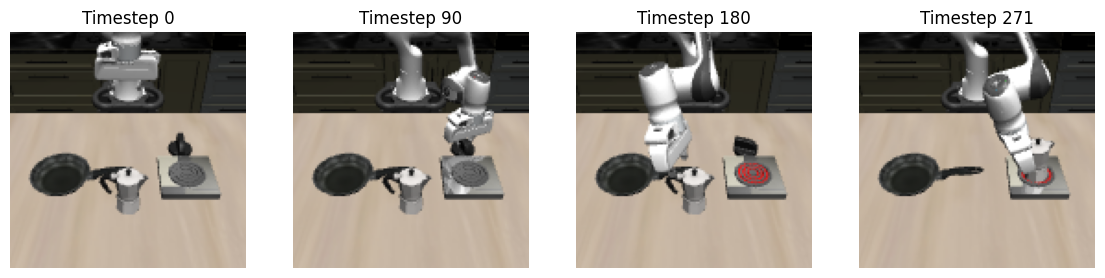

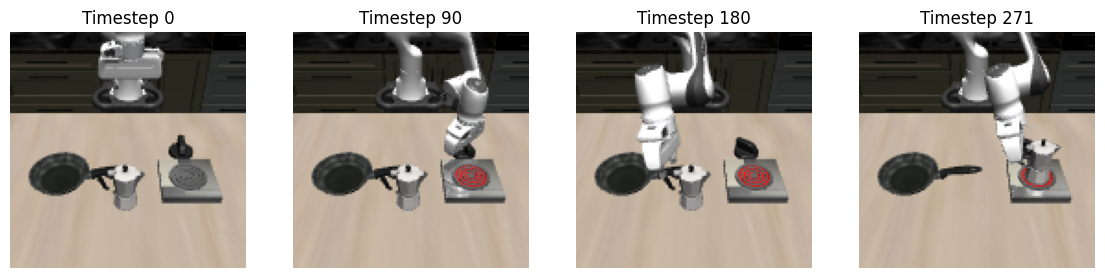

In [7]:
def visualize_demo(file_path, demo_id="demo_0"):
    with h5py.File(file_path, "r") as f:
        # Get the demonstration and camera observations
        demo = f["data"][demo_id]
        images = demo["obs"]["agentview_rgb"]

        # Select 4 evenly spaced frames
        frames = np.linspace(0, len(images) - 1, 4, dtype=int)

        # Display the frames
        fig, axes = plt.subplots(1, 4, figsize=(14, 4))

        for ax, t in zip(axes, frames):
            ax.imshow(np.flipud(images[t]))
            ax.set_title(f"Timestep {t}")
            ax.axis("off")

        plt.show()
        
print(len(files))
visualize_demo(files[0], "demo_0")
visualize_demo(files[0], "demo_49")

## Analyzing Expert Actions

Each LIBERO demonstration contains a sequence of 7-dimensional robot actions.

We will plot each action dimension over time to understand how the robot moves during a demonstration and examine the magnitude and variation of its control commands.

 LIBERO stores normalized relative end-effector commands, not absolute robot positions or Euler angles

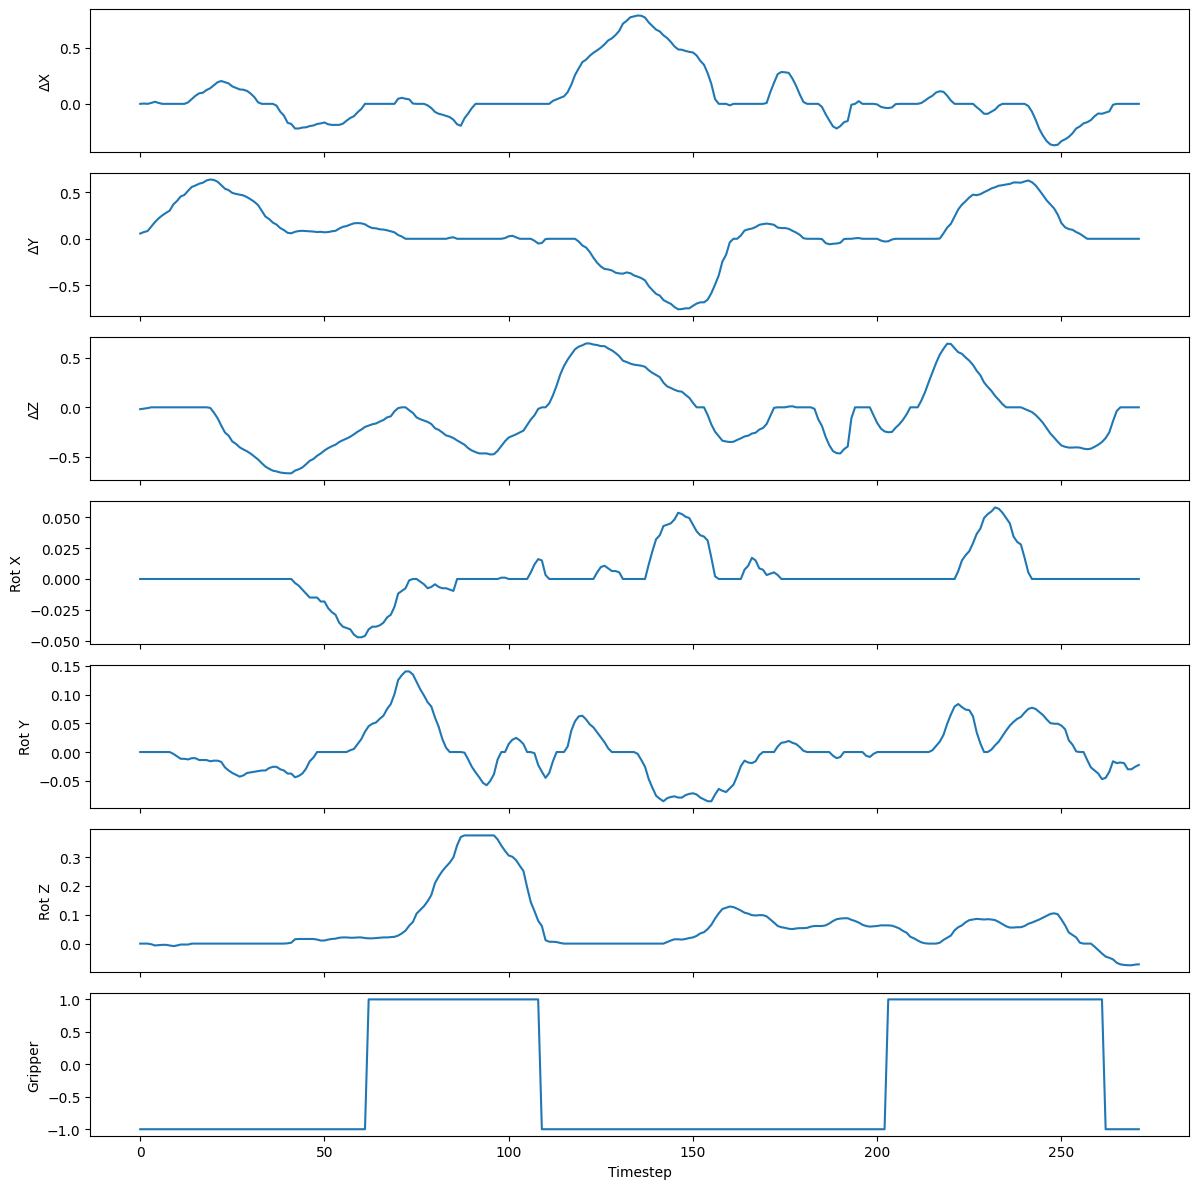

In [8]:
def plot_demo_actions(file_path, demo_id="demo_0"):
    with h5py.File(file_path, "r") as f:
        # Load expert actions
        actions = f["data"][demo_id]["actions"][:]

    labels = ["ΔX", "ΔY", "ΔZ", "Rot X", "Rot Y", "Rot Z", "Gripper"]

    # Plot each action dimension
    fig, axes = plt.subplots(7, 1, figsize=(12, 12), sharex=True)

    for i, ax in enumerate(axes):
        ax.plot(actions[:, i])
        ax.set_ylabel(labels[i])

    axes[-1].set_xlabel("Timestep")
    plt.tight_layout()
    plt.show()
plot_demo_actions(files[0])

## Trajectory Length Analysis
Demonstrations of the same task may contain different numbers of timesteps due to variations in robot movement and execution.

We analyze trajectory lengths to understand the dataset's temporal characteristics and identify differences between demonstrations.

In [9]:
def plot_demo_lengths(file_path):
    with h5py.File(file_path, "r") as f:
        # Get the length of each demonstration
        lengths = [
            len(demo["actions"])
            for name, demo in f["data"].items()
            if name.startswith("demo_")
        ]

    # Display trajectory statistics
    print("Demonstrations:", len(lengths))
    print("Mean length:", np.mean(lengths))
    print("Median length:", np.median(lengths))
    print("Shortest:", min(lengths))
    print("Longest:", max(lengths))

    # Visualize trajectory length distribution
    plt.hist(lengths, bins=15, edgecolor="black")
    plt.xlabel("Trajectory Length (Timesteps)")
    plt.ylabel("Number of Demonstrations")
    plt.title(file_path.stem)
    plt.show()

Demonstrations: 50
Mean length: 265.96
Median length: 262.5
Shortest: 219
Longest: 340


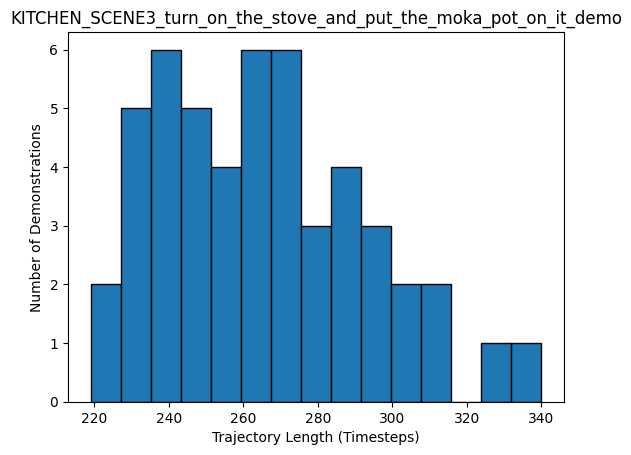

In [10]:
plot_demo_lengths(files[0])

## Dataset indexing

To support efficient retrieval and skill discovery, we construct a metadata index containing each task's language instruction, demonstration identifier, file path, and trajectory length.

This allows us to identify and select demonstrations without repeatedly loading large observation arrays into memory.

We index both LIBERO-90 (prior demonstrations) and LIBERO-10 (downstream tasks).

In [11]:


index = build_dataset_index(dataset_root)

print("Total demonstrations:", len(index))
print(index.groupby("suite").size())

display(index.head())

Total demonstrations: 5000
suite
libero_10     500
libero_90    4500
dtype: int64


,suite,task,instruction,demo_id,file_path,length
0,libero_90,KITCHEN_SCENE10_close_the_top_drawer_of_the_ca...,close the top drawer of the cabinet and put th...,demo_0,/blue/uf-eig/FILLMEIN/HSR-Replication/d...,197
1,libero_90,KITCHEN_SCENE10_close_the_top_drawer_of_the_ca...,close the top drawer of the cabinet and put th...,demo_1,/blue/uf-eig/FILLMEIN/HSR-Replication/d...,207
2,libero_90,KITCHEN_SCENE10_close_the_top_drawer_of_the_ca...,close the top drawer of the cabinet and put th...,demo_2,/blue/uf-eig/FILLMEIN/HSR-Replication/d...,284
3,libero_90,KITCHEN_SCENE10_close_the_top_drawer_of_the_ca...,close the top drawer of the cabinet and put th...,demo_3,/blue/uf-eig/FILLMEIN/HSR-Replication/d...,223
4,libero_90,KITCHEN_SCENE10_close_the_top_drawer_of_the_ca...,close the top drawer of the cabinet and put th...,demo_4,/blue/uf-eig/FILLMEIN/HSR-Replication/d...,210


In [46]:
# Count unique tasks and demonstrations per suite
print(index.groupby("suite").agg(
    tasks=("task", "nunique"),
    demonstrations=("demo_id", "count"),
    mean_length=("length", "mean")
))


# Save metadata

# Save metadata to Blue storage
index_path = dataset_root.parent / "dataset_index.csv"

index.to_csv(index_path, index=False)

print("Saved:", index_path)

           tasks  demonstrations  mean_length
suite                                        
libero_10     10             500   276.180000
libero_90     90            4500   148.676222
Saved: /blue/uf-eig/FILLMEIN/HSR-Replication/dataset_index.csv


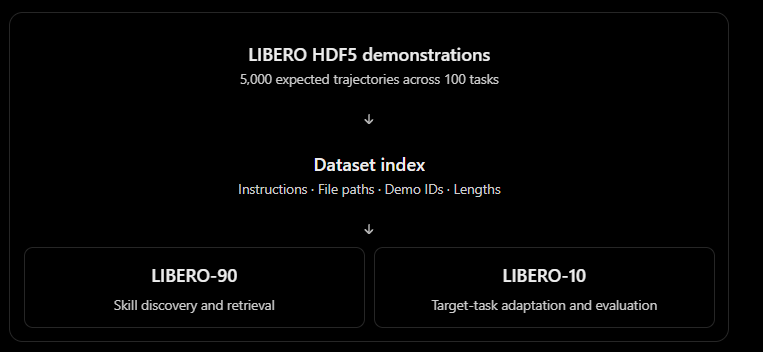

## Conclusion

We explored the **LIBERO-90** and **LIBERO-10** datasets, including HDF5 structure, expert demonstrations, robot actions, and trajectory lengths.

We also created a dataset index containing task instructions, demonstration IDs, file paths, and trajectory lengths.

### Connection to HSR

- **LIBERO-90:** Prior demonstrations used for skill discovery and retrieval.
- **LIBERO-10:** Target tasks used for few-shot adaptation and evaluation.

### Next

We will extract LIBERO-90 task instructions, encode them using **BERT**, and apply **K-means clustering (K=10)** to discover reusable skill groups.